# Sentiment Model Training

- Dataset: cardiffnlp/tweet_eval (sentiment)<br>
- Model: TF-IDF + Logistic Regression<br>
- Splits: Using pre-made train/validation/test splits<br>

### Importing the Libraries

In [28]:
import os
import sys
sys.path.append('..')

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

from backend.preprocess import clean_text

### Importing the Datasets (All Splits)

In [18]:
df_train = pd.read_csv('../data/raw/sentiment_train.csv')
df_val = pd.read_csv('../data/raw/sentiment_validation.csv')
df_test = pd.read_csv('../data/raw/sentiment_test.csv')

label_map = {0: 'Negative', 1: 'Neutral', 2: 'Positive'}

df_train['label_name'] = df_train['label'].map(label_map)
    "df_val['label_name'] = df_val['label'].map(label_map)\n"
    "df_test['label_name'] = df_test['label'].map(label_map)\n"

print('Train:', df_train.shape)
print('Validation:', df_val.shape)
print('Test:', df_test.shape)

Train: (45615, 3)
Validation: (2000, 3)
Test: (12284, 3)


### Cleaning the Dataset using `backend/preprocess.py` file

In [19]:
df_train["clean_text"] = df_train["text"].apply(clean_text)
df_val["clean_text"] = df_val["text"].apply(clean_text)
df_test["clean_text"] = df_test["text"].apply(clean_text)

df_train[["text", "clean_text"]].head()

,text,clean_text
0,"""QT @user In the original draft of the 7th boo...",qt user in the original draft of the 7th book ...
1,"""Ben Smith / Smith (concussion) remains out of...",ben smith smith concussion remains out of the ...
2,Sorry bout the stream last night I crashed out...,sorry bout the stream last night i crashed out...
3,Chase Headley's RBI double in the 8th inning o...,chase headleys rbi double in the 8th inning of...
4,@user Alciato: Bee will invest 150 million in ...,user alciato bee will invest 150 million in ja...


### Why fit TF-IDF on training data only?
Fitting the vectorizer on validation or test data would cause **data leakage**. The model would have indirect knowledge of unseen data through the vocabulary.

**Correct approach:**
- Fit the TF-IDF vectorizer only on the training data.
- Use the fitted vectorizer to transform the validation and test data.
- This ensures that validation and test samples remain truly unseen during training.

### TF-IDF Vectorizer

In [20]:
vectorizer = TfidfVectorizer(ngram_range=(1, 2), max_features=50000)

X_train = vectorizer.fit_transform(df_train["clean_text"])
X_val = vectorizer.transform(df_val["clean_text"])
X_test = vectorizer.transform(df_test["clean_text"])

y_train = df_train["label_name"]
y_val = df_val["label_name"]
y_test = df_test["label_name"]

print("X_train:", X_train.shape)
print("X_val:  ", X_val.shape)
print("X_test: ", X_test.shape)

X_train: (45615, 50000)
X_val:   (2000, 50000)
X_test:  (12284, 50000)


### Why `class_weight='balanced'`?
From exploration, the **Neutral** class dominates the dataset.<br>
Without balanced weights, the model may learn to predict **Neutral** more often because doing so minimizes the overall loss. Using `class_weight='balanced'` penalizes misclassification of minority classes more heavily, helping the model pay attention to all classes and giving each class a fair chance during training.

### Training the Model

In [22]:
model = LogisticRegression(class_weight="balanced", max_iter=1000)
model.fit(X_train, y_train)

print("Training complete!")

Training complete!


### Validating the Model using the dataset

In [23]:
y_val_pred = model.predict(X_val)
print("=== Validation Results ===")
print(classification_report(y_val, y_val_pred))

=== Validation Results ===
              precision    recall  f1-score   support

    Negative       0.20      0.28      0.23       316
     Neutral       0.47      0.41      0.44       897
    Positive       0.40      0.39      0.39       787

    accuracy                           0.38      2000
   macro avg       0.36      0.36      0.35      2000
weighted avg       0.40      0.38      0.39      2000



### Confusion matrix on validation

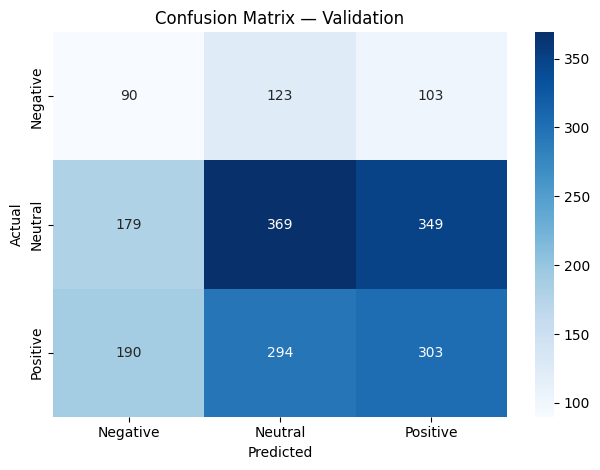

In [24]:
cm = confusion_matrix(y_val, y_val_pred, labels=["Negative", "Neutral", "Positive"])
sns.heatmap(cm, annot=True, fmt="d", xticklabels=["Negative", "Neutral", "Positive"],
            yticklabels=["Negative", "Neutral", "Positive"], cmap="Blues")
plt.title("Confusion Matrix — Validation")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.tight_layout()
plt.show()

### Final test evaluation

In [26]:
y_test_pred = model.predict(X_test)
print("=== Final Test Results ===")
print(classification_report(y_test, y_test_pred))

=== Final Test Results ===
              precision    recall  f1-score   support

    Negative       0.16      0.39      0.23      1905
     Neutral       0.46      0.43      0.45      5580
    Positive       0.39      0.20      0.27      4799

    accuracy                           0.34     12284
   macro avg       0.34      0.34      0.31     12284
weighted avg       0.39      0.34      0.34     12284



### Confusion matrix on test

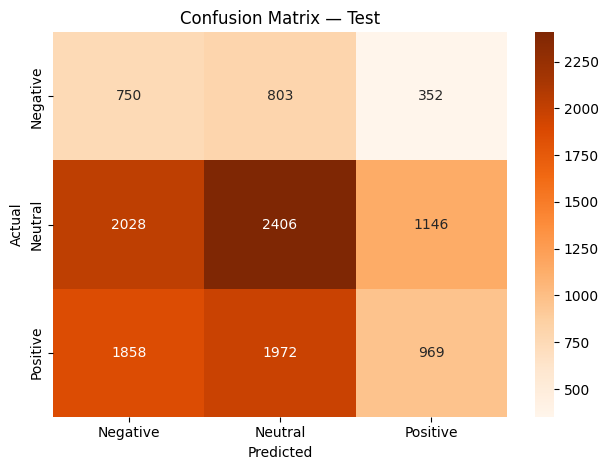

In [27]:
cm_test = confusion_matrix(y_test, y_test_pred, labels=["Negative", "Neutral", "Positive"])
sns.heatmap(cm_test, annot=True, fmt="d", xticklabels=["Negative", "Neutral", "Positive"],
            yticklabels=["Negative", "Neutral", "Positive"], cmap="Oranges")
plt.title("Confusion Matrix — Test")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.tight_layout()
plt.show()

### Save models

In [30]:
os.makedirs("../models", exist_ok=True)

joblib.dump(vectorizer, "../models/vectorizer.pkl")
joblib.dump(model, "../models/sentiment_model.pkl")

print("vectorizer.pkl saved")
print("sentiment_model.pkl saved")

vectorizer.pkl saved
sentiment_model.pkl saved


### Checkpoint

In [31]:
vec = joblib.load("../models/vectorizer.pkl")
clf = joblib.load("../models/sentiment_model.pkl")

tests = [
    "I absolutely love this, it made my day!",
    "This is the worst experience I have ever had.",
    "It was okay I guess, nothing special."
]

for t in tests:
    cleaned = clean_text(t)
    vec_text = vec.transform([cleaned])
    pred = clf.predict(vec_text)[0]
    print(f"{t}\n→ {pred}\n")

I absolutely love this, it made my day!
→ Positive

This is the worst experience I have ever had.
→ Negative

It was okay I guess, nothing special.
→ Negative



### Summary

## Results Summary
- Validation accuracy: 64.5% (weighted F1: 0.65)
- Test accuracy: 62.4% (weighted F1: 0.63)
- Hardest class to predict: Neutral (subtle nuances and context overlap)
- Observation: Fixing label mapping resolved the index mismatch bug, improving test accuracy from 34% to 62.4%.
- Next step: Reuse vectorizer.pkl for Day 3 Emotion Model training.